In [1]:
from google.colab import files
uploaded = files.upload()

Saving kaggle.json to kaggle.json


In [2]:
!pip install -q kaggle

!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

In [3]:
!kaggle datasets list -s us-accidents

ref                                                             title                                                     size  lastUpdated                 downloadCount  voteCount  usabilityRating  
--------------------------------------------------------------  --------------------------------------------------  ----------  --------------------------  -------------  ---------  ---------------  
sobhanmoosavi/us-accidents                                      US Accidents (2016 - 2023)                           684855912  2023-05-28 00:54:47.207000         195873       2730                1  
jonbown/us-2020-traffic-accidents                               US Traffic Accidents                                  82475267  2023-02-26 16:53:20.873000           4408         70                1  
sobhanmons/analysis-of-us-accidents                             Analysis of US accidents                             189092490  2022-01-13 15:19:44.777000            387          6        0.5882353  


In [4]:
!kaggle datasets download -d sobhanmoosavi/us-accidents

Dataset URL: https://www.kaggle.com/datasets/sobhanmoosavi/us-accidents
License(s): CC-BY-NC-SA-4.0
100% 653M/653M [00:08<00:00, 79.4MB/s]



In [5]:
!unzip -q us-accidents.zip -d /content/accidents

In [6]:
import os

print(os.listdir('/content/accidents'))

['US_Accidents_March23.csv']


In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load first 100,000 rows
df = pd.read_csv('/content/accidents/US_Accidents_March23.csv', nrows=100000)

df.head()

,ID,Source,Severity,Start_Time,End_Time,Start_Lat,Start_Lng,End_Lat,End_Lng,Distance(mi),...,Roundabout,Station,Stop,Traffic_Calming,Traffic_Signal,Turning_Loop,Sunrise_Sunset,Civil_Twilight,Nautical_Twilight,Astronomical_Twilight
0,A-1,Source2,3,2016-02-08 05:46:00,2016-02-08 11:00:00,39.865147,-84.058723,NaN,NaN,0.01,...,False,False,False,False,False,False,Night,Night,Night,Night
1,A-2,Source2,2,2016-02-08 06:07:59,2016-02-08 06:37:59,39.928059,-82.831184,NaN,NaN,0.01,...,False,False,False,False,False,False,Night,Night,Night,Day
2,A-3,Source2,2,2016-02-08 06:49:27,2016-02-08 07:19:27,39.063148,-84.032608,NaN,NaN,0.01,...,False,False,False,False,True,False,Night,Night,Day,Day
3,A-4,Source2,3,2016-02-08 07:23:34,2016-02-08 07:53:34,39.747753,-84.205582,NaN,NaN,0.01,...,False,False,False,False,False,False,Night,Day,Day,Day
4,A-5,Source2,2,2016-02-08 07:39:07,2016-02-08 08:09:07,39.627781,-84.188354,NaN,NaN,0.01,...,False,False,False,False,True,False,Day,Day,Day,Day


In [8]:

print("Dataset Shape:", df.shape)

df.info()

print("\nMissing Values:")
print(df.isnull().sum().head(15))

Dataset Shape: (100000, 46)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 46 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   ID                     100000 non-null  object 
 1   Source                 100000 non-null  object 
 2   Severity               100000 non-null  int64  
 3   Start_Time             100000 non-null  object 
 4   End_Time               100000 non-null  object 
 5   Start_Lat              100000 non-null  float64
 6   Start_Lng              100000 non-null  float64
 7   End_Lat                0 non-null       float64
 8   End_Lng                0 non-null       float64
 9   Distance(mi)           100000 non-null  float64
 10  Description            100000 non-null  object 
 11  Street                 100000 non-null  object 
 12  City                   99999 non-null   object 
 13  County                 100000 non-null  object 
 14  State    

In [9]:

print("Missing Values Before Cleaning:")
print(df.isnull().sum().head(15))

df = df.dropna(subset=['Start_Time', 'Severity', 'City'])

df = df.drop_duplicates()

# Convert Start_Time into date format
df['Start_Time'] = pd.to_datetime(df['Start_Time'])

# Check final dataset
print("\nFinal Dataset Shape:", df.shape)
print("\nMissing Values After Cleaning:")
print(df.isnull().sum().head(15))

Missing Values Before Cleaning:
ID                   0
Source               0
Severity             0
Start_Time           0
End_Time             0
Start_Lat            0
Start_Lng            0
End_Lat         100000
End_Lng         100000
Distance(mi)         0
Description          0
Street               0
City                 1
County               0
State                0
dtype: int64

Final Dataset Shape: (99999, 46)

Missing Values After Cleaning:
ID                  0
Source              0
Severity            0
Start_Time          0
End_Time            0
Start_Lat           0
Start_Lng           0
End_Lat         99999
End_Lng         99999
Distance(mi)        0
Description         0
Street              0
City                0
County              0
State               0
dtype: int64


Severity
2    55024
3    44844
1       98
4       33
Name: count, dtype: int64


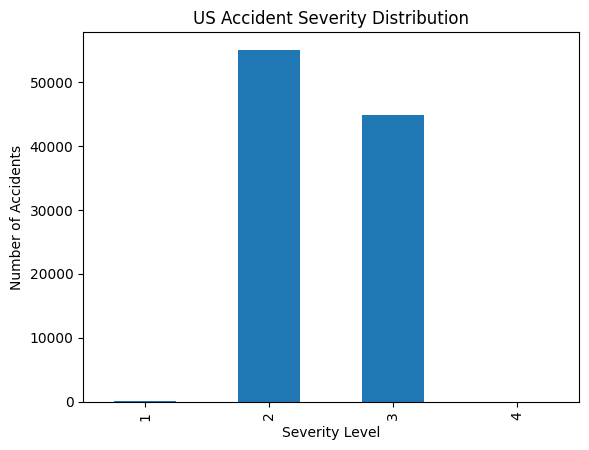

In [10]:
# Count accident severity
print(df['Severity'].value_counts())

df['Severity'].value_counts().sort_index().plot(kind='bar')

plt.title('US Accident Severity Distribution')
plt.xlabel('Severity Level')
plt.ylabel('Number of Accidents')
plt.show()

Time_Period
Afternoon    31599
Evening      30842
Morning      27202
Night        10356
Name: count, dtype: int64


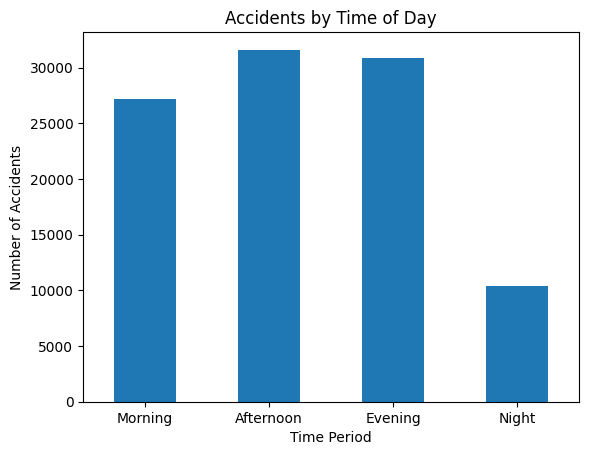

In [11]:
# Extract hour from start time
df['Hour'] = df['Start_Time'].dt.hour

# Divide accidents into time periods
def get_time(hour):
    if hour < 6:
        return 'Night'
    elif hour < 12:
        return 'Morning'
    elif hour < 18:
        return 'Afternoon'
    else:
        return 'Evening'

df['Time_Period'] = df['Hour'].apply(get_time)

# Count accidents
print(df['Time_Period'].value_counts())

df['Time_Period'].value_counts().reindex(
    ['Morning', 'Afternoon', 'Evening', 'Night']
).plot(kind='bar')

plt.title('Accidents by Time of Day')
plt.xlabel('Time Period')
plt.ylabel('Number of Accidents')
plt.xticks(rotation=0)
plt.show()

Weather_Condition
Clear               57254
Overcast            10255
Mostly Cloudy        8829
Partly Cloudy        8260
Scattered Clouds     5684
Light Rain           3211
Haze                 2097
Fair                 1039
Rain                  829
Heavy Rain            202
Name: count, dtype: int64


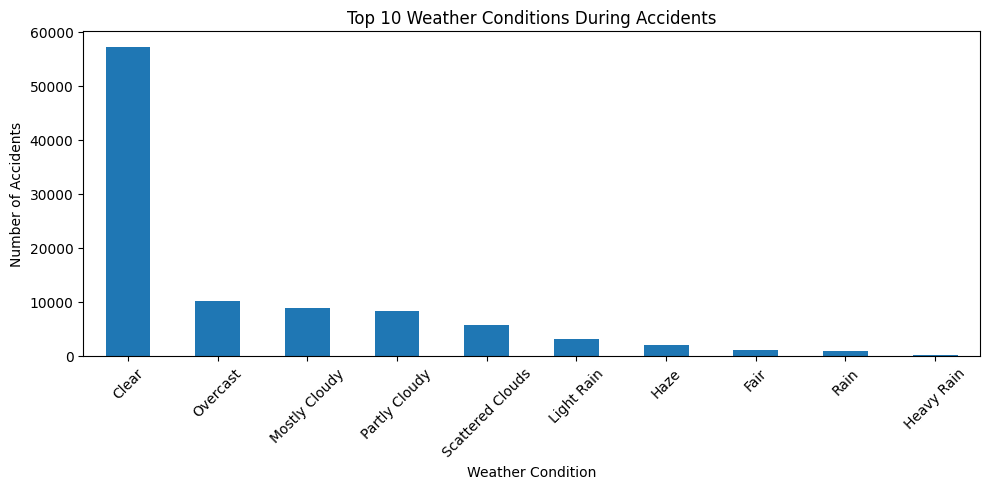

In [12]:
# Count accidents by weather
weather = df['Weather_Condition'].value_counts().head(10)

print(weather)

weather.plot(kind='bar', figsize=(10,5))

plt.title('Top 10 Weather Conditions During Accidents')
plt.xlabel('Weather Condition')
plt.ylabel('Number of Accidents')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [13]:
# Count accidents across the full dataset
chunks = pd.read_csv(
    '/content/accidents/US_Accidents_March23.csv',
    usecols=['State'],
    chunksize=500000
)

state_counts = pd.concat(
    [chunk['State'].value_counts() for chunk in chunks]
).groupby(level=0).sum()

# Display top 10 states
print(state_counts.sort_values(ascending=False).head(10))

State
CA    1741433
FL     880192
TX     582837
SC     382557
NY     347960
NC     338199
VA     303301
PA     296620
MN     192084
OR     179660
Name: count, dtype: int64


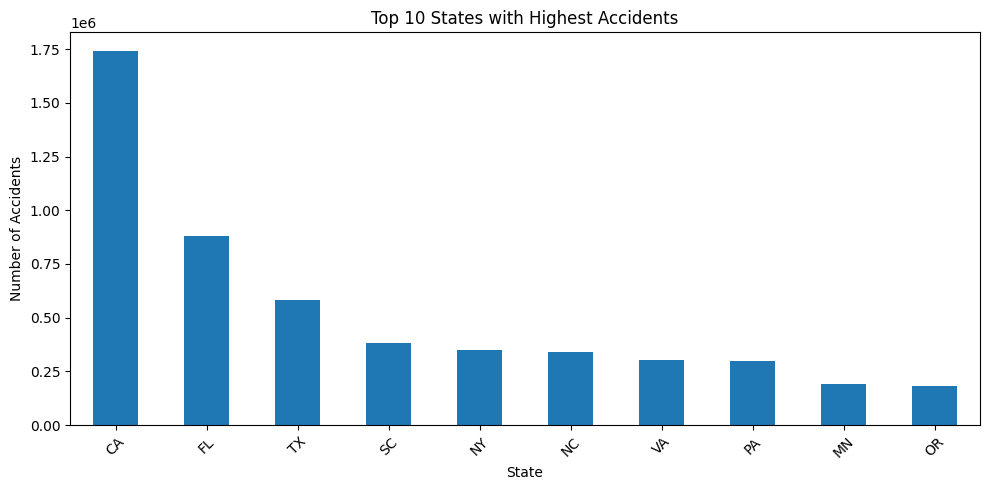

In [14]:
plt.figure(figsize=(10, 5))

state_counts.nlargest(10).plot(kind='bar')

plt.title('Top 10 States with Highest Accidents')
plt.xlabel('State')
plt.ylabel('Number of Accidents')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


**Results and Observations**

1. The full dataset contains accident records from multiple US states.
2. California recorded the highest number of accidents.
3. Florida and Texas also reported a high number of accidents.
4. The top 10 states show significant differences in accident counts.
5. State-wise analysis helps identify areas with a higher number of recorded accidents.

**Conclusion**

The analysis shows that California has the highest number of recorded accidents, followed by Florida and Texas. This analysis helps identify states with higher accident records and supports further investigation into traffic safety.

